# 쇼핑몰에서 누가 자주 오고 많이 사는지 분석해서 단골 찾기

H&M 패션 쇼핑몰의 거래·고객·상품 데이터(상품 이미지 포함)를 분석한다. 이 노트북은 `src/pipeline.py`의 `DataAnalyzer` 클래스를 불러와 다음 순서로 진행한다.

1. 데이터 로드와 기본 탐색
2. 피처 엔지니어링(상품명, 이미지)
3. 결측치 대치와 이상치 처리
4. 통계 분석과 시각화
5. RFM 고객 세분화

In [1]:
import sys
from pathlib import Path

# 이 노트북은 notebooks/ 폴더에서 실행되므로, 부모 폴더(프로젝트 루트)를
# import 경로에 추가해 src/pipeline.py를 불러올 수 있게 한다.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import DataAnalyzer

import matplotlib.pyplot as plt

# 차트의 한글이 깨지지 않도록 설치된 폰트 중 첫 번째를 쓴다.
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 로드

`DataAnalyzer().load_data()`는 거래·고객·상품 CSV 세 개를 읽는다. 이때 두 가지를 지킨다.

- `customer_id`, `article_id` 같은 ID 컬럼은 **문자열**로 읽는다. 숫자로 읽으면 `0706016001` 같은 상품 ID의 앞자리 0이 사라져 이미지 경로와 다른 테이블과의 연결이 끊긴다.
- `order_date`, `first_sold_date`는 **날짜형**으로 읽는다.

In [2]:
analyzer = DataAnalyzer().load_data()

tables = {
    "transactions (거래)": analyzer.transactions,
    "customers (고객)": analyzer.customers,
    "articles (상품)": analyzer.articles,
}
for name, df in tables.items():
    print(f"{name:<22} {df.shape[0]:>6,}행 x {df.shape[1]}열")

transactions (거래)      27,728행 x 5열
customers (고객)          2,000행 x 7열
articles (상품)           1,500행 x 29열


In [3]:
print("article_id 예시:", analyzer.articles["article_id"].iloc[0])
print("article_id 자료형:", analyzer.articles["article_id"].dtype)

order_dates = analyzer.transactions["order_date"]
print("order_date 자료형:", order_dates.dtype)
print("order_date 범위:", order_dates.min().date(), "~", order_dates.max().date())

article_id 예시: 0706016001
article_id 자료형: str
order_date 자료형: datetime64[us]
order_date 범위: 2019-09-23 ~ 2020-09-22


## 2. 기본 탐색

세 테이블에 `head()`(앞 5행), `info()`(컬럼별 자료형과 비어 있지 않은 값의 개수), `describe()`(수치 컬럼의 개수·평균·표준편차·사분위수)를 실행해 구조를 파악한다. 모든 해석은 **수치 근거 1개 이상 + 시사점 1문장 이상**으로 쓴다.

### 2-1. 거래 데이터 (`transactions`)

거래 1행은 고객이 상품 1개를 산 기록이다. RFM 분석(Recency·Frequency·Monetary)의 재료가 된다.

In [4]:
analyzer.transactions.head()

,order_date,customer_id,article_id,amount,sales_channel_id
0,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0739680002,0.005797,1
1,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0739680002,0.005797,1
2,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0796232001,0.033881,2
3,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0796232001,0.033881,2
4,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0179123001,0.014508,1


In [5]:
analyzer.transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 27728 entries, 0 to 27727
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_date        27728 non-null  datetime64[us]
 1   customer_id       27728 non-null  str           
 2   article_id        27728 non-null  str           
 3   amount            27728 non-null  float64       
 4   sales_channel_id  27728 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 1.1 MB


In [6]:
analyzer.transactions.describe().round(4)

,order_date,amount,sales_channel_id
count,27728,27728.0000,27728.0000
mean,2020-03-27 22:12:17.449509,0.0281,1.7064
min,2019-09-23 00:00:00,0.0007,1.0000
25%,2019-12-23 00:00:00,0.0169,1.0000
50%,2020-04-08 00:00:00,0.0254,2.0000
75%,2020-06-25 00:00:00,0.0339,2.0000
max,2020-09-22 00:00:00,0.3373,2.0000
std,NaN,0.0187,0.4554


In [7]:
tx = analyzer.transactions
n_customers = tx["customer_id"].nunique()
print(f"거래 {len(tx):,}건, 고유 고객 {n_customers:,}명, 고객당 평균 {len(tx) / n_customers:.2f}건")
print("판매 채널별 건수:", tx["sales_channel_id"].value_counts().to_dict())
print(f"amount 최댓값 / 중앙값 = {tx['amount'].max() / tx['amount'].median():.1f}배")

거래 27,728건, 고유 고객 2,000명, 고객당 평균 13.86건
판매 채널별 건수: {2: 19587, 1: 8141}
amount 최댓값 / 중앙값 = 13.3배


**해석 — 거래 데이터**

- **수치 근거:** 거래는 27,728건, 고객은 2,000명으로 고객당 평균 약 13.9건이다. 결제 금액 `amount`는 평균 0.0281, 중앙값 0.0254, 최댓값 0.3373로, 평균이 중앙값보다 크고 최댓값은 중앙값의 약 13배다.
- **시사점:** 소수의 고가 거래가 평균을 끌어올리는 오른쪽으로 긴 분포로 보인다. `amount`는 원화나 달러가 아닌 상대값이므로, 금액은 "몇 원"이 아니라 "다른 고객·거래와의 상대 크기"로 해석해야 하고, 고객별 금액 합계(RFM의 Monetary)를 볼 때도 큰 거래의 영향을 감안해야 한다.

### 2-2. 고객 데이터 (`customers`)

고객 1행은 고객 1명이다. `FN`과 `Active`는 값이 1이거나 비어 있는 표시 컬럼이다.

In [8]:
analyzer.customers.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00511323d252c93be07a61a61891bc8ff0ffdf547573fc...,1.0,1.0,ACTIVE,Regularly,58.0,f3618817f36086a3a71cacf19369ba411083206758cb7b...
1,006614ef971c0097e28a98c8c1d7127088c7dae2721eac...,NaN,NaN,PRE-CREATE,NONE,50.0,b935d7a9b07fc2e9779f88dbda6d14570116f00b56c912...
2,006e3b308be2c29584e79e4c87df8c7fd45ebe5ce2bbb8...,1.0,1.0,ACTIVE,Regularly,21.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
3,006e4ef0f8243b60eb0e94c1d851254f8cf0ce45fbb8b8...,NaN,NaN,ACTIVE,NONE,58.0,ad18f8a527437d83ef46d2d2e267bb0b674187067fa5f2...
4,00998ab46e0ad7e77e4ea9dc0e2109c15e055d0c20acfc...,1.0,1.0,ACTIVE,Regularly,51.0,d2bb93612bd38b18f1939df4949f871f3085d99d0ffdf6...


In [9]:
analyzer.customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   str    
 1   FN                      715 non-null    float64
 2   Active                  704 non-null    float64
 3   club_member_status      1995 non-null   str    
 4   fashion_news_frequency  1971 non-null   str    
 5   age                     1981 non-null   float64
 6   postal_code             2000 non-null   str    
dtypes: float64(3), str(4)
memory usage: 109.5 KB


In [10]:
analyzer.customers.describe().round(2)

,FN,Active,age
count,715.0,704.0,1981.00
mean,1.0,1.0,35.65
std,0.0,0.0,14.06
min,1.0,1.0,17.00
25%,1.0,1.0,24.00
50%,1.0,1.0,31.00
75%,1.0,1.0,48.00
max,1.0,1.0,79.00


In [11]:
customers = analyzer.customers
missing = customers.isna().sum().to_frame("결측 개수")
missing["결측률(%)"] = (missing["결측 개수"] / len(customers) * 100).round(1)
print("FN 값:", sorted(customers["FN"].dropna().unique()), "/ Active 값:", sorted(customers["Active"].dropna().unique()))
missing

FN 값: [np.float64(1.0)] / Active 값: [np.float64(1.0)]


,결측 개수,결측률(%)
customer_id,0,0.0
FN,1285,64.2
Active,1296,64.8
club_member_status,5,0.2
fashion_news_frequency,29,1.5
age,19,1.0
postal_code,0,0.0


**해석 — 고객 데이터**

- **수치 근거:** 고객 2,000명 중 나이(`age`)가 있는 사람은 1,981명이고 19명은 비어 있다. 나이의 중앙값은 31세, 평균은 35.65세이고, 25%가 24세 이하, 75%가 48세 이하다.
- **시사점:** 평균이 중앙값보다 높아 젊은 층에 몰려 있고 나이가 많은 쪽으로 꼬리가 긴 분포다. 나이 결측은 19명(0.95%)으로 비중이 작지만, 결측 처리(5단계)에서 그룹별 통계로 대치할 대상이다.
- **수치 근거:** `FN`은 1,285명(64.2%), `Active`는 1,296명(64.8%)이 비어 있고, 값이 있는 경우는 모두 1 하나뿐이다.
- **시사점:** 원본이 빈 값의 의미("아니오"인지 "모름"인지)를 설명하지 않으므로 빈 값을 0으로 단정하지 않고, 의미를 확인하기 전에는 분석 변수로 쓰지 않는다.

### 2-3. 상품 데이터 (`articles`)

상품 1행은 상품 1개다. 상품명(텍스트), 가격·판매량(수치), 종류·색상(범주), 첫 판매일(날짜), 이미지 파일 경로를 한 표에 갖고 있다.

In [12]:
analyzer.articles.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,sales_count,avg_price,first_sold_date,image_path
0,0706016001,0706016,Jade HW Skinny Denim TRS,272,Trousers,Garment Lower body,1010016,Solid,9,Black,...,Divided,53,Divided Collection,1009,Trousers,High-waisted jeans in washed superstretch deni...,30209,0.032122,2018-11-27,images/070/0706016001.jpg
1,0720125001,0720125,SUPREME RW tights,273,Leggings/Tights,Garment Lower body,1010016,Solid,9,Black,...,Sport,5,Ladies H&M Sport,1005,Jersey Fancy,Sports tights in fast-drying functional fabric...,17182,0.032350,2019-05-28,images/072/0720125001.jpg
2,0706016002,0706016,Jade HW Skinny Denim TRS,272,Trousers,Garment Lower body,1010016,Solid,71,Light Blue,...,Divided,53,Divided Collection,1009,Trousers,High-waisted jeans in washed superstretch deni...,16872,0.031901,2018-11-02,images/070/0706016002.jpg
3,0372860001,0372860,7p Basic Shaftless,302,Socks,Socks & Tights,1010016,Solid,9,Black,...,Ladieswear,62,"Womens Nightwear, Socks & Tigh",1021,Socks and Tights,Fine-knit trainer socks in a soft cotton blend.,15429,0.012942,2018-09-20,images/037/0372860001.jpg
4,0759871002,0759871,Tilda tank,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Divided,80,Divided Complements Other,1002,Jersey Basic,"Cropped, fitted top in cotton jersey with narr...",15295,0.006127,2019-03-05,images/075/0759871002.jpg


In [13]:
analyzer.articles.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 29 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   article_id                    1500 non-null   str           
 1   product_code                  1500 non-null   str           
 2   prod_name                     1500 non-null   str           
 3   product_type_no               1500 non-null   int64         
 4   product_type_name             1500 non-null   str           
 5   product_group_name            1500 non-null   str           
 6   graphical_appearance_no       1500 non-null   int64         
 7   graphical_appearance_name     1500 non-null   str           
 8   colour_group_code             1500 non-null   int64         
 9   colour_group_name             1500 non-null   str           
 10  perceived_colour_value_id     1500 non-null   int64         
 11  perceived_colour_value_name   1500 non-nu

In [14]:
analyzer.articles.describe().round(4)

,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no,sales_count,avg_price,first_sold_date
count,1500.000,1.500000e+03,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500
mean,249.120,1.010015e+06,23.1347,3.2427,7.3447,2580.7493,2.4607,35.1307,1010.4787,3000.9987,0.0256,2019-09-12 08:44:09.600000
min,-1.000,1.010001e+06,3.0000,1.0000,-1.0000,1201.0000,1.0000,2.0000,1001.0000,1675.0000,0.0016,2018-09-20 00:00:00
25%,253.000,1.010016e+06,9.0000,2.0000,5.0000,1626.0000,1.0000,15.0000,1005.0000,1954.0000,0.0161,2019-05-20 00:00:00
50%,265.000,1.010016e+06,10.0000,4.0000,5.0000,1676.0000,1.0000,26.0000,1009.0000,2387.0000,0.0242,2019-11-04 00:00:00
75%,273.000,1.010016e+06,20.0000,4.0000,9.0000,3708.0000,2.0000,60.0000,1017.0000,3286.5000,0.0319,2020-02-19 00:00:00
max,512.000,1.010028e+06,93.0000,7.0000,20.0000,8617.0000,26.0000,80.0000,1025.0000,30209.0000,0.1221,2020-09-03 00:00:00
std,69.692,5.893100e+00,25.2994,1.2695,4.9467,1773.9739,5.3477,22.5356,6.7538,1906.0904,0.0129,NaN


In [15]:
articles = analyzer.articles
print("관심 있는 수치 컬럼만 다시 보기 (번호 컬럼 제외)")
display(articles[["sales_count", "avg_price"]].describe().round(4))
for col in ["sales_count", "avg_price"]:
    print(f"{col}: 최댓값 / 중앙값 = {articles[col].max() / articles[col].median():.1f}배")

missing = articles.isna().sum().to_frame("결측 개수")
missing["결측률(%)"] = (missing["결측 개수"] / len(articles) * 100).round(1)
missing[missing["결측 개수"] > 0]

관심 있는 수치 컬럼만 다시 보기 (번호 컬럼 제외)


,sales_count,avg_price
count,1500.0000,1500.0000
mean,3000.9987,0.0256
std,1906.0904,0.0129
min,1675.0000,0.0016
25%,1954.0000,0.0161
50%,2387.0000,0.0242
75%,3286.5000,0.0319
max,30209.0000,0.1221


sales_count: 최댓값 / 중앙값 = 12.7배
avg_price: 최댓값 / 중앙값 = 5.0배


,결측 개수,결측률(%)
detail_desc,2,0.1
image_path,6,0.4


**해석 — 상품 데이터**

- **수치 근거:** 상품 1,500개의 판매 건수 `sales_count`는 중앙값 2,387건인데 최댓값은 30,209건으로 중앙값의 약 12.7배다. 평균 판매가 `avg_price`도 중앙값 0.0242, 최댓값 0.1221로 약 5.0배 차이가 난다.
- **시사점:** 판매량이 소수의 베스트셀러에 크게 쏠려 있고, 가격도 한쪽으로 긴 분포다. 이 두 컬럼은 이상치 탐지(6단계)의 대상이다.
- **수치 근거:** 결측은 이미지 경로 6개(0.4%)와 상세 설명 2개뿐이다.
- **시사점:** 이미지 경로가 비어 있는 상품은 4단계의 이미지 평균·표준편차를 계산할 수 없으므로 5단계의 결측 대치 대상이 된다.

### 2-4. 데이터 구조 점검

Subject 4장이 요구하는 조건(1,000행 이상, 8컬럼 이상, 데이터 유형 3종 이상, RFM용 컬럼)을 확인한다.

In [16]:
import pandas as pd

scale = pd.DataFrame({name: {"행": df.shape[0], "열": df.shape[1]} for name, df in tables.items()}).T
scale["1,000행 이상"] = scale["행"] >= 1000
scale["8컬럼 이상"] = scale["열"] >= 8
scale

,행,열,"1,000행 이상",8컬럼 이상
transactions (거래),27728,5,True,False
customers (고객),2000,7,True,False
articles (상품),1500,29,True,True


In [17]:
# 수치형·날짜형·텍스트·이미지·ID는 직접 나열하고, 나머지는 범주형으로 분류한다.
non_categorical = {
    "transactions": {"수치형": ["amount"], "날짜형": ["order_date"],
                     "식별자(ID)": ["customer_id", "article_id"]},
    "customers": {"수치형": ["age"], "식별자(ID)": ["customer_id", "postal_code"]},
    "articles": {"수치형": ["sales_count", "avg_price"], "날짜형": ["first_sold_date"],
                 "텍스트": ["prod_name", "detail_desc"], "이미지(파일 경로)": ["image_path"],
                 "식별자(ID)": ["article_id", "product_code"]},
}

rows = []
for table_name, types in non_categorical.items():
    df = getattr(analyzer, table_name)
    assigned = [c for cols in types.values() for c in cols]
    categorical = [c for c in df.columns if c not in assigned]
    for type_name, cols in {**types, "범주형": categorical}.items():
        rows.append({"테이블": table_name, "유형": type_name, "컬럼 수": len(cols), "컬럼": ", ".join(cols)})
pd.set_option("display.max_colwidth", 80)
type_table = pd.DataFrame(rows)
type_table

,테이블,유형,컬럼 수,컬럼
0,transactions,수치형,1,amount
1,transactions,날짜형,1,order_date
2,transactions,식별자(ID),2,"customer_id, article_id"
3,transactions,범주형,1,sales_channel_id
4,customers,수치형,1,age
5,customers,식별자(ID),2,"customer_id, postal_code"
6,customers,범주형,4,"FN, Active, club_member_status, fashion_news_frequency"
7,articles,수치형,2,"sales_count, avg_price"
8,articles,날짜형,1,first_sold_date
9,articles,텍스트,2,"prod_name, detail_desc"


In [18]:
# 분류가 실제 자료형과 맞는지 확인한다.
ok_numeric = all(pd.api.types.is_numeric_dtype(getattr(analyzer, t)[c])
                 for t, types in non_categorical.items() for c in types.get("수치형", []))
ok_date = all(pd.api.types.is_datetime64_any_dtype(getattr(analyzer, t)[c])
              for t, types in non_categorical.items() for c in types.get("날짜형", []))
print("수치형 컬럼이 모두 숫자 자료형:", ok_numeric)
print("날짜형 컬럼이 모두 날짜 자료형:", ok_date)
print("이미지 경로가 있는 상품:", analyzer.articles["image_path"].notna().sum(), "개")

수치형 컬럼이 모두 숫자 자료형: True
날짜형 컬럼이 모두 날짜 자료형: True
이미지 경로가 있는 상품: 1494 개


In [19]:
# 정수로 저장돼 있지만 값이 "번호표"인 컬럼: 고유값이 적으면 범주로 본다.
numeric_cols = analyzer.articles.select_dtypes("number").columns
code_cols = [c for c in numeric_cols if c not in ("sales_count", "avg_price")]
pd.DataFrame({"고유값 수": analyzer.articles[code_cols].nunique(), "전체 행 수": len(analyzer.articles)})

,고유값 수,전체 행 수
product_type_no,48,1500
graphical_appearance_no,25,1500
colour_group_code,39,1500
perceived_colour_value_id,6,1500
perceived_colour_master_id,17,1500
department_no,82,1500
index_group_no,4,1500
section_no,25,1500
garment_group_no,19,1500


In [20]:
# RFM 계산에 필요한 컬럼이 거래 테이블에 있는지 확인한다.
required = ["customer_id", "order_date", "amount"]
{col: col in analyzer.transactions.columns for col in required}

{'customer_id': True, 'order_date': True, 'amount': True}

**해석 — 데이터 구조**

- **수치 근거:** 상품 테이블은 1,500행 × 29열로 1,000행·8컬럼 기준을 충족한다. 거래 테이블(27,728행 × 5열)과 고객 테이블(2,000행 × 7열)은 8컬럼에 못 미치므로 이 기준은 상품 테이블로 확인하고, 거래 테이블은 RFM 계산용(`customer_id`, `order_date`, `amount` 포함)으로 쓴다.
- **시사점:** 이 데이터는 수치형(`sales_count`, `avg_price`, `amount`, `age`), 범주형(상품 테이블 21개 등), 날짜형(`order_date`, `first_sold_date`) 3종에 더해 텍스트(`prod_name`)와 이미지(1,494개 경로)까지 갖췄다. 이미지와 상품명은 숫자 피처로 바꿔야 다른 컬럼과 함께 분석할 수 있다(3·4단계).
- **수치 근거:** 상품 테이블의 정수형 컬럼 중 `sales_count`를 뺀 9개(`product_type_no` 등)는 고유값이 4~82개뿐이고 1,500개 행에 반복된다. `sales_channel_id`(값 1·2), `FN`·`Active`(값 1)도 숫자로 저장돼 있다.
- **시사점:** 이 컬럼들은 크기를 비교하는 수치가 아니라 종류를 가르는 번호이므로 평균·상관계수를 구하지 않고 범주로 취급한다. `describe()`에 함께 나오더라도 통계 해석에서는 제외한다.

## 3. 텍스트 파생 변수

상품명(`prod_name`)은 문자열이라 가격·판매량 같은 숫자와 함께 계산할 수 없다. 그래서 `DataAnalyzer.add_text_features()`로 숫자 컬럼 2개를 만든다.

| 새 컬럼 | 뜻 |
| --- | --- |
| `prod_name_word_count` | 상품명의 단어 수 |
| `prod_name_length` | 상품명의 글자 수(공백 포함) |

**계산 기준(결정과 이유)**

- **둘 다 만든다.** 과제는 "단어 수 또는 문자열 길이"를 요구하지만, 둘 다 한 줄씩이라 비용이 거의 없고 두 값이 얼마나 같이 움직이는지도 나중에 비교할 수 있다.
- **단어는 공백으로 나눈 조각이다.** 공백이 연속된 상품명이 11개(이름 6종) 있어서, 공백 한 칸 기준(`split(" ")`)으로 나누면 빈 조각이 단어로 세어진다. 연속 공백을 하나로 보는 `split()`을 쓴다.
- **구두점은 정리하지 않는다.** `Tilly (1)`은 2단어, `Vanessa 2-pack`은 2단어다. 정리 규칙을 더하면 기준이 늘고, 과제가 요구하지도 않는다.
- **글자 수는 원본 그대로 센다.** 공백도 한 글자로 센다.
- **결측은 결측으로 둔다.** 이 컬럼에는 결측이 없지만 다른 텍스트 컬럼에 같은 메서드를 쓸 때 0으로 오해되지 않도록 한다.

In [21]:
analyzer.add_text_features()
analyzer.articles[["prod_name", "prod_name_word_count", "prod_name_length"]].head()

,prod_name,prod_name_word_count,prod_name_length
0,Jade HW Skinny Denim TRS,5,24
1,SUPREME RW tights,3,17
2,Jade HW Skinny Denim TRS,5,24
3,7p Basic Shaftless,3,18
4,Tilda tank,2,10


**직접 센 값과 비교한다.** 상품명 6개의 단어 수와 글자 수를 손으로 세어 적고, 계산된 컬럼 값과 같은지 확인한다. 마지막 상품명은 `HW` 뒤에 공백이 2개 있는 경우다.

In [22]:
# (단어 수, 글자 수)를 직접 세어 적은 값
hand_counted = {
    "Mona": (1, 4),
    "Tilly (1)": (2, 9),
    "Vanessa 2-pack": (2, 14),
    "Jade HW Skinny Denim TRS": (5, 24),
    "Charlotte Brazilian Aza.Low 2p": (4, 30),
    "Maja HW  WovenTRS": (3, 17),  # HW 뒤에 공백 2개
}

articles = analyzer.articles
rows = []
for name, (words, length) in hand_counted.items():
    row = articles[articles["prod_name"] == name].iloc[0]
    rows.append({"상품명": name,
                 "직접 센 단어 수": words, "컬럼 단어 수": row["prod_name_word_count"],
                 "직접 센 글자 수": length, "컬럼 글자 수": row["prod_name_length"]})
check = pd.DataFrame(rows)
check["일치"] = ((check["직접 센 단어 수"] == check["컬럼 단어 수"])
                & (check["직접 센 글자 수"] == check["컬럼 글자 수"]))
check

,상품명,직접 센 단어 수,컬럼 단어 수,직접 센 글자 수,컬럼 글자 수,일치
0,Mona,1,1,4,4,True
1,Tilly (1),2,2,9,9,True
2,Vanessa 2-pack,2,2,14,14,True
3,Jade HW Skinny Denim TRS,5,5,24,24,True
4,Charlotte Brazilian Aza.Low 2p,4,4,30,30,True
5,Maja HW WovenTRS,3,3,17,17,True


In [23]:
# 공백이 연속된 상품명에서 두 가지 나누기의 차이
name = "Maja HW  WovenTRS"
print(f"split()    : {name.split()} -> {len(name.split())}단어")
print(f"split(' ') : {name.split(' ')} -> {len(name.split(' '))}단어")
print("공백이 연속된 상품명:", articles["prod_name"].str.contains(r"\s{2,}").sum(), "개")

split()    : ['Maja', 'HW', 'WovenTRS'] -> 3단어
split(' ') : ['Maja', 'HW', '', 'WovenTRS'] -> 4단어
공백이 연속된 상품명: 11 개


In [24]:
display(articles[["prod_name_word_count", "prod_name_length"]].describe().round(2))
print("단어 수 분포:", articles["prod_name_word_count"].value_counts().sort_index().to_dict())

one_word = (articles["prod_name_word_count"] == 1).sum()
mid_words = articles["prod_name_word_count"].between(2, 4).sum()
print(f"1단어 상품명: {one_word:,}개 ({one_word / len(articles) * 100:.1f}%)")
print(f"2~4단어 상품명: {mid_words:,}개 ({mid_words / len(articles) * 100:.1f}%)")
print("고유 상품명:", articles["prod_name"].nunique(), "개 / 전체", len(articles), "행")
print(f"행 x 열: {articles.shape[0]:,} x {articles.shape[1]} (추가 전 29열)")

,prod_name_word_count,prod_name_length
count,1500.00,1500.00
mean,2.75,15.54
std,1.22,6.79
min,1.00,3.00
25%,2.00,10.00
50%,3.00,15.00
75%,4.00,21.00
max,6.00,30.00


단어 수 분포: {1: 251, 2: 434, 3: 399, 4: 288, 5: 112, 6: 16}
1단어 상품명: 251개 (16.7%)
2~4단어 상품명: 1,121개 (74.7%)
고유 상품명: 854 개 / 전체 1500 행
행 x 열: 1,500 x 31 (추가 전 29열)


**해석 — 텍스트 파생 변수**

- **수치 근거:** 상품명은 평균 2.75단어, 평균 15.54글자이고, 단어 수는 1~6개, 글자 수는 3~30자 범위다. 2~4단어인 상품명이 1,121개(74.7%)이고 1단어는 251개(16.7%)다.
- **시사점:** 이름이 짧고 값의 폭이 좁아서 같은 값을 가진 상품이 많다. 이 피처만으로 상품을 구분하는 힘은 약할 수 있으며, 가격·판매량과 관계가 있는지는 통계 분석(7단계)에서 상관계수로 확인한다.
- **수치 근거:** 상품 1,500개의 고유한 상품명은 854개뿐이다.
- **시사점:** 색상만 다른 상품은 이름이 같아서 같은 값이 반복된다. 이 피처는 "디자인"에 가까운 정보이므로 상품 1,500개를 서로 독립된 표본으로 보지 않도록 해석에 주의한다.

## 4. 이미지 피처

이미지 한 장은 `(세로, 가로, 채널)` 모양의 **숫자 배열**이다. 채널은 빨강·초록·파랑 3개이고, 각 칸의 값은 0(가장 어두움)~255(가장 밝음)이다. 이 배열 전체의 **평균**은 이미지의 밝기, **표준편차**는 밝고 어두운 부분이 얼마나 갈리는지(대비)를 나타낸다. 이미지 한 장을 숫자 2개로 요약하면 가격·판매량 같은 다른 컬럼과 같은 표에서 분석할 수 있다. 이 계산을 `DataAnalyzer.add_image_features()`가 맡는다.

**계산 기준(결정과 이유)**

- **이미지의 모든 값(세로·가로·채널 전부)으로 평균과 표준편차를 하나씩 구한다.** 과제가 이미지당 평균·표준편차 컬럼을 요구하므로 채널별로 나누지 않는다. 표준편차는 NumPy 기본값(모집단, `ddof=0`)이다. 이미지의 모든 픽셀을 다 가지고 있어서 표본이 아니기 때문이다.
- **반복문은 파일을 여는 곳에만 남기고, 한 장 안의 픽셀 계산은 NumPy 배열 연산으로 한다.** 파일 1,494개를 열려면 파일 단위 반복은 피할 수 없다. 이미지를 전부 쌓아 한 번에 계산하면 반복이 더 줄어 보이지만, 한 장이 약 6.1MB라서 1,494장을 쌓으면 약 9.1GB가 필요하다.
- **다운샘플링은 기본적으로 하지 않고(`step=1`), 인자로만 지원한다.** 전체 해상도로 계산해도 충분히 빠르고 값이 정확하다. `step`을 키우면 `arr[::step, ::step]` 슬라이싱으로 픽셀을 건너뛰어 계산하며, 이미지가 커졌을 때 시간을 줄이는 조절 장치다.
- **크기가 다른 이미지도 그대로 계산한다.** 이미지별로 따로 계산하므로 크기를 맞출 필요가 없다.
- **이미지 경로가 없는 상품은 결측으로 둔다.** 5단계에서 그룹별 통계로 채운다.

파일: 0706016001.jpg
shape (세로, 가로, 채널): (1750, 1166, 3)
dtype: uint8 | 값 범위: 0 ~ 255
이미지 1장 크기: 6,121,500바이트 -> 1,494장을 쌓으면 약 9.1GB
전체 평균: 172.69 | 좌상단 50x50 영역 평균: 235.22


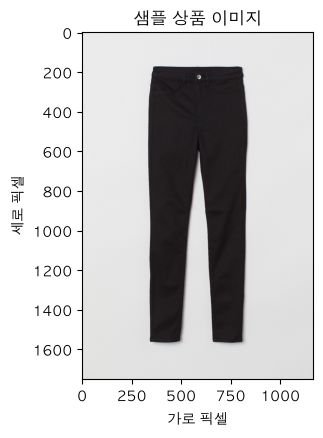

In [25]:
from matplotlib.image import imread

sample_path = analyzer.data_dir / analyzer.articles["image_path"].dropna().iloc[0]
image = imread(sample_path)  # 이미지 파일 -> NumPy 배열
print("파일:", sample_path.name)
print("shape (세로, 가로, 채널):", image.shape)
print("dtype:", image.dtype, "| 값 범위:", image.min(), "~", image.max())
print(f"이미지 1장 크기: {image.nbytes:,}바이트 -> 1,494장을 쌓으면 약 {image.nbytes * 1494 / 1e9:.1f}GB")
print(f"전체 평균: {image.mean():.2f} | 좌상단 50x50 영역 평균: {image[:50, :50].mean():.2f}")

plt.figure(figsize=(3, 4.5))
plt.imshow(image)
plt.title("샘플 상품 이미지")
plt.xlabel("가로 픽셀")
plt.ylabel("세로 픽셀")
plt.show()

**반복문과 NumPy 배열 연산 비교.** 같은 이미지의 평균과 표준편차를 (1) 값을 하나씩 도는 파이썬 반복문과 (2) NumPy 배열 연산으로 구해 값과 시간을 비교한다. 시간은 실행할 때마다 조금씩 달라진다.

In [26]:
import time

# (1) 파이썬 반복문: 값을 하나씩 더하고, 평균과의 차이를 하나씩 제곱해서 더한다.
pixels = image.ravel().tolist()
start = time.perf_counter()
total = 0
for value in pixels:
    total += value
loop_mean = total / len(pixels)
squared = 0.0
for value in pixels:
    squared += (value - loop_mean) ** 2
loop_std = (squared / len(pixels)) ** 0.5
loop_seconds = time.perf_counter() - start

# (2) NumPy 배열 연산: 배열 전체에 한 번에 적용한다.
start = time.perf_counter()
numpy_mean, numpy_std = image.mean(), image.std()
numpy_seconds = time.perf_counter() - start

print(f"값의 개수: {len(pixels):,}")
print(f"반복문: 평균 {loop_mean:.6f}, 표준편차 {loop_std:.6f} ({loop_seconds:.3f}초)")
print(f"NumPy : 평균 {numpy_mean:.6f}, 표준편차 {numpy_std:.6f} ({numpy_seconds:.4f}초)")
print("두 방법의 값이 같은가:", abs(loop_mean - numpy_mean) < 1e-6 and abs(loop_std - numpy_std) < 1e-6)
print(f"반복문이 NumPy보다 약 {loop_seconds / numpy_seconds:.0f}배 오래 걸림")

값의 개수: 6,121,500
반복문: 평균 172.688792, 표준편차 88.992240 (0.396초)
NumPy : 평균 172.688792, 표준편차 88.992240 (0.0093초)
두 방법의 값이 같은가: True
반복문이 NumPy보다 약 42배 오래 걸림


In [27]:
analyzer.add_image_features()
analyzer.articles[["article_id", "image_path", "img_mean", "img_std"]].head()

,article_id,image_path,img_mean,img_std
0,0706016001,images/070/0706016001.jpg,172.688792,88.992240
1,0720125001,images/072/0720125001.jpg,173.214989,85.564607
2,0706016002,images/070/0706016002.jpg,196.585072,57.726606
3,0372860001,images/037/0372860001.jpg,195.916482,76.869613
4,0759871002,images/075/0759871002.jpg,153.846229,99.466212


In [28]:
articles = analyzer.articles

# 위에서 따로 읽어 계산한 이미지 1장의 값과 새 컬럼 값을 비교한다.
first = articles[articles["image_path"].notna()].iloc[0]
print(f"직접 계산: 평균 {image.mean():.6f}, 표준편차 {image.std():.6f}")
print(f"컬럼 값  : 평균 {first['img_mean']:.6f}, 표준편차 {first['img_std']:.6f}")
print("일치:", first["img_mean"] == image.mean() and first["img_std"] == image.std())

# 이미지 경로가 없는 상품은 결측이다.
no_image = articles[articles["image_path"].isna()]
print(f"이미지 경로가 없는 상품 {len(no_image)}개 / img_mean 결측 {articles['img_mean'].isna().sum()}개, img_std 결측 {articles['img_std'].isna().sum()}개")
no_image[["article_id", "colour_group_name", "img_mean", "img_std"]]

직접 계산: 평균 172.688792, 표준편차 88.992240
컬럼 값  : 평균 172.688792, 표준편차 88.992240
일치: True
이미지 경로가 없는 상품 6개 / img_mean 결측 6개, img_std 결측 6개


,article_id,colour_group_name,img_mean,img_std
5,0610776002,Black,NaN,NaN
12,0610776001,White,NaN,NaN
262,0408875001,Black,NaN,NaN
401,0179208001,Black,NaN,NaN
694,0212629004,Black,NaN,NaN
1429,0788632002,Dark Beige,NaN,NaN


In [29]:
# 다운샘플링(step=4)이 값을 얼마나 바꾸는지 비교한다. 이미지를 다시 읽으므로 몇 초 걸린다.
fast = DataAnalyzer().load_data().add_image_features(step=4)
diff_mean = (fast.articles["img_mean"] - articles["img_mean"]).abs()
diff_std = (fast.articles["img_std"] - articles["img_std"]).abs()
print(f"step=4와 step=1의 최대 차이: 평균 {diff_mean.max():.3f}, 표준편차 {diff_std.max():.3f} (값의 범위는 0~255)")

step=4와 step=1의 최대 차이: 평균 0.384, 표준편차 0.499 (값의 범위는 0~255)


In [30]:
display(articles[["img_mean", "img_std"]].describe().round(2))
print(f"행 x 열: {articles.shape[0]:,} x {articles.shape[1]} (추가 전 31열)")

,img_mean,img_std
count,1494.00,1494.00
mean,189.16,62.75
std,29.43,31.13
min,30.13,2.64
25%,168.60,38.44
50%,191.03,70.81
75%,212.91,89.80
max,237.17,117.56


행 x 열: 1,500 x 33 (추가 전 31열)


**해석 — 이미지 피처**

- **수치 근거:** 이미지 1,494장의 평균 밝기 `img_mean`은 30.13~237.17(중앙값 191.03), 표준편차 `img_std`는 2.64~117.56(중앙값 70.81)이다. 샘플 이미지는 전체 평균이 172.69인데 좌상단 50x50 영역(배경 부분)의 평균은 235.22로 더 밝다.
- **시사점:** `img_mean`은 상품 자체의 색이 아니라 상품과 배경을 합친 밝기다. 이 샘플에서는 밝은 배경이 이미지의 큰 부분을 차지하므로, 어두운 옷도 평균이 높게 나올 수 있다. 이 피처를 해석할 때 "상품이 밝다"가 아니라 "사진 전체가 밝다"로 읽어야 한다. (샘플 1장으로 확인한 것이며 모든 이미지가 같다고 단정하지 않는다.)
- **수치 근거:** 다운샘플링 `step=4`로 계산한 값은 `step=1`과 최대 0.384(평균), 0.499(표준편차)만 달랐다.
- **시사점:** 값의 범위가 0~255인 데 비해 차이가 작아서, 이미지가 훨씬 많거나 커졌을 때 `step`을 키워 계산 시간을 줄여도 피처의 의미는 거의 유지된다.
- **수치 근거:** 이미지 경로가 없는 상품 6개는 두 피처가 결측이다.
- **시사점:** 이 결측은 5단계에서 그룹별 통계로 대치해야 이후 분석에 쓸 수 있다.

## 5. 결측치 처리

**결측치**는 값이 비어 있는 칸이다. 비어 있는 채로 평균이나 상관계수를 구하면 그 행이 계산에서 빠지거나 오류가 난다. 그래서 먼저 어느 컬럼에 얼마나 비어 있는지 현황을 보고, 채울 컬럼을 골라 `DataAnalyzer.handle_missing_values()`로 채운다.

**결정과 이유**

- **채울 컬럼은 `age`(고객 나이), `img_mean`, `img_std`(이미지 피처)다.** 이후 분석에 쓰는 숫자 컬럼이면서 결측이 적다.
- **그룹별(GroupBy) 중앙값으로 채운다.** 전체 중앙값 하나로 채우면 그룹마다 다른 특성이 사라진다. 나이는 회원 상태(`club_member_status`)별로, 이미지 피처는 상품 색상 그룹(`colour_group_name`)별로 나눈다. 중앙값을 쓰는 이유는 한쪽으로 치우친 값에 평균만큼 끌려가지 않고, 나이가 정수로 유지되기 때문이다.
- **그룹 값이 결측이면 전체 중앙값으로 채운다.** 그룹을 알 수 없는 행은 그룹별 통계를 쓸 수 없다.
- **채우지 않는 컬럼이 있다.** `FN`·`Active`(비어 있는 것이 무엇을 뜻하는지 원본이 설명하지 않고 대부분이 비어 있다), `club_member_status`·`fashion_news_frequency`(분석에 쓰지 않는 범주), `detail_desc`(텍스트), `image_path`(이미지가 원래 없는 상품)이다.
- **같은 컬럼을 덮어쓴다.** 이후 단계가 같은 컬럼 이름으로 이어서 쓰도록 하기 위해서다. 대치 전후 비교는 호출 전에 복사해 둔 값으로 한다.
- **대치의 위험.** 비어 있는 값을 모두 같은 통계값으로 채우면 값들이 중앙값 근처에 몰려 **분산이 줄어들고**, 그룹마다 다른 값으로 채우면 **그룹 간 차이가 실제보다 커 보일** 수 있다. 아래에서 수치로 확인한다.

In [31]:
# 대치 전 결측 현황 (세 테이블에서 결측이 있는 컬럼만)
analyzer.missing_report()

,table,column,missing,missing_pct
0,customers,FN,1285,64.25
1,customers,Active,1296,64.80
2,customers,club_member_status,5,0.25
3,customers,fashion_news_frequency,29,1.45
4,customers,age,19,0.95
5,articles,detail_desc,2,0.13
6,articles,image_path,6,0.40
7,articles,img_mean,6,0.40
8,articles,img_std,6,0.40


In [32]:
# 대치 전 값을 복사해 둔다(전후 비교용).
before = {
    "age": analyzer.customers["age"].copy(),
    "img_mean": analyzer.articles["img_mean"].copy(),
    "img_std": analyzer.articles["img_std"].copy(),
}

analyzer.handle_missing_values("customers", "age", group_col="club_member_status", strategy="median")
analyzer.handle_missing_values("articles", "img_mean", group_col="colour_group_name", strategy="median")
analyzer.handle_missing_values("articles", "img_std", group_col="colour_group_name", strategy="median")
print("대치 완료")

대치 완료


In [33]:
# 대치 전후 결측 수와, 원래 값이 있던 행이 바뀌지 않았는지 확인한다.
after = {
    "age": analyzer.customers["age"],
    "img_mean": analyzer.articles["img_mean"],
    "img_std": analyzer.articles["img_std"],
}
rows = []
for name, filled in after.items():
    was_missing = before[name].isna()
    rows.append({"컬럼": name,
                 "대치 전 결측": int(was_missing.sum()),
                 "대치 후 결측": int(filled.isna().sum()),
                 "원래 값이 바뀐 행": int((filled[~was_missing] != before[name][~was_missing]).sum())})
pd.DataFrame(rows)

,컬럼,대치 전 결측,대치 후 결측,원래 값이 바뀐 행
0,age,19,0,0
1,img_mean,6,0,0
2,img_std,6,0,0


In [34]:
# 나이: 그룹별 중앙값과, 실제로 채워진 값
customers = analyzer.customers
club = customers["club_member_status"]
print("대치 전 값 기준 그룹별 나이 중앙값:", before["age"].groupby(club).median().to_dict(), "/ 전체 중앙값:", before["age"].median())
print("그룹별로 값이 있는 인원:", before["age"].groupby(club).count().to_dict())

imputed = customers[before["age"].isna()]
summary = imputed.groupby("club_member_status", dropna=False)["age"].agg(["count", "min", "max"])
summary.columns = ["대치된 인원", "채워진 값(최소)", "채워진 값(최대)"]
summary

대치 전 값 기준 그룹별 나이 중앙값: {'ACTIVE': 31.0, 'PRE-CREATE': 43.0} / 전체 중앙값: 31.0
그룹별로 값이 있는 인원: {'ACTIVE': 1905, 'PRE-CREATE': 75}


,대치된 인원,채워진 값(최소),채워진 값(최대)
club_member_status,,,
ACTIVE,4,31.0,31.0
PRE-CREATE,11,43.0,43.0
NaN,4,31.0,31.0


In [35]:
# 이미지 피처: 대치된 상품 6개와, 해당 색상 그룹의 중앙값
articles = analyzer.articles
filled = articles[before["img_mean"].isna()][["article_id", "colour_group_name", "img_mean", "img_std"]]
display(filled)
print("색상 그룹별 img_mean 중앙값:", before["img_mean"].groupby(articles["colour_group_name"]).median()[filled["colour_group_name"].unique()].round(2).to_dict())

,article_id,colour_group_name,img_mean,img_std
5,0610776002,Black,170.757254,90.102616
12,0610776001,White,231.133106,6.106457
262,0408875001,Black,170.757254,90.102616
401,0179208001,Black,170.757254,90.102616
694,0212629004,Black,170.757254,90.102616
1429,0788632002,Dark Beige,177.949393,64.982699


색상 그룹별 img_mean 중앙값: {'Black': 170.76, 'White': 231.13, 'Dark Beige': 177.95}


In [36]:
# 대치 후 결측 현황
analyzer.missing_report()

,table,column,missing,missing_pct
0,customers,FN,1285,64.25
1,customers,Active,1296,64.80
2,customers,club_member_status,5,0.25
3,customers,fashion_news_frequency,29,1.45
4,articles,detail_desc,2,0.13
5,articles,image_path,6,0.40


In [37]:
# 대치 전후 분포 변화: 평균과 표준편차
rows = []
for name, filled in after.items():
    rows.append({"컬럼": name,
                 "대치 전 평균": before[name].mean(), "대치 후 평균": filled.mean(),
                 "대치 전 표준편차": before[name].std(), "대치 후 표준편차": filled.std()})
change = pd.DataFrame(rows).set_index("컬럼")
change["표준편차 변화(%)"] = (change["대치 후 표준편차"] / change["대치 전 표준편차"] - 1) * 100
change.round(2)

,대치 전 평균,대치 후 평균,대치 전 표준편차,대치 후 표준편차,표준편차 변화(%)
컬럼,,,,,
age,35.65,35.67,14.06,14.01,-0.38
img_mean,189.16,189.13,29.43,29.41,-0.08
img_std,62.75,62.79,31.13,31.14,0.01


**해석 — 결측치 처리**

- **수치 근거:** 나이가 비어 있던 고객 19명은 회원 상태가 `PRE-CREATE`인 사람이 11명, `ACTIVE`가 4명, 회원 상태도 비어 있는 사람이 4명이다. 값이 있는 고객 기준 나이 중앙값은 `ACTIVE` 31세, `PRE-CREATE` 43세, 전체 31세다.
- **시사점:** 전체 중앙값(31세) 하나로 채웠다면 `PRE-CREATE` 고객 11명의 나이를 12살 낮게 채웠을 것이다. 그룹별로 채우면 이 차이가 반영된다. 회원 상태가 비어 있는 4명은 그룹 통계를 쓸 수 없어 전체 중앙값 31세로 채웠다.
- **수치 근거:** 이미지 피처가 비어 있던 상품 6개는 색상 그룹이 Black 4개, White 1개, Dark Beige 1개이고, 각 그룹의 중앙값으로 채웠다.
- **시사점:** 이미지가 없는 상품도 같은 색상 계열의 전형적인 밝기·대비 값을 갖게 되어 이후 분석에서 빠지지 않는다. 다만 이 값은 실제 이미지에서 계산한 것이 아니라 추정값이다.
- **수치 근거:** 대치 후 나이의 표준편차는 14.06에서 14.01로 -0.38%, `img_mean`은 29.43에서 29.41로 -0.08% 달라졌다. 나이 평균은 35.65에서 35.67가 되었다.
- **시사점:** 비어 있던 비율이 작아서(나이 0.95%, 이미지 피처 0.40%) 분산 축소와 평균 이동은 거의 없다. 같은 방식을 결측이 훨씬 많은 컬럼(`FN`·`Active`는 64%대)에 쓰면 값이 한 통계값 근처에 몰려 분산이 크게 줄고 그룹 간 차이가 과장될 수 있다. 이것이 그 컬럼들을 채우지 않은 이유다.
- **수치 근거:** `PRE-CREATE` 그룹은 값이 있는 고객이 75명뿐이다(`ACTIVE`는 1,905명).
- **시사점:** 작은 그룹의 중앙값은 몇 명의 값에 크게 좌우되므로 11명에게 채운 43세는 그룹 평균에 가까운 추정일 뿐 개인의 실제 나이가 아니다.

## 6. 이상치 탐지와 처리 (IQR 방식)

**이상치**는 대부분의 값에서 크게 벗어난 값이다. 이 노트북은 **IQR(사분위 범위) 방식**으로 찾는다.

- 값을 작은 순으로 줄 세웠을 때 1/4 지점의 값이 **Q1**, 3/4 지점의 값이 **Q3**이다. 둘의 차이 **IQR = Q3 − Q1**은 가운데 절반의 값이 퍼진 폭이다.
- 경계는 **아래 경계 = Q1 − 임계값 × IQR**, **위 경계 = Q3 + 임계값 × IQR**이다. 경계 밖의 값이 이상치이고, 임계값은 보통 1.5를 쓴다.
- 박스플롯의 상자는 Q1~Q3이고, 상자 밖에 찍히는 점이 이 규칙의 이상치다.

`DataAnalyzer`의 `iqr_bounds()`가 경계를 계산하고, `detect_outliers()`가 이상치 행을 찾고, `treat_outliers()`가 이상치를 경계값으로 바꾼 새 컬럼을 만든다.

**결정과 이유**

- **대상은 상품 테이블의 `sales_count`(판매 건수)와 `avg_price`(평균 판매가)다.** 앞에서 두 컬럼 모두 평균이 중앙값보다 크고 오른쪽으로 길게 치우친 것을 확인했다.
- **임계값은 기본 1.5로 하고, 3.0과 개수를 비교한다.**
- **이상치는 지우지 않고 경계값으로 바꾼다.** 지우면 상품 행이 줄어든다. 처리 결과는 원본을 덮어쓰지 않고 새 컬럼 `{컬럼}_clipped`에 저장해서 처리 전후를 비교할 수 있게 한다.
- **경계와 정확히 같은 값은 이상치가 아니다.** `값 < 아래 경계` 또는 `값 > 위 경계`일 때만 이상치다.
- **거래 테이블의 `amount`는 처리하지 않는다.** 이 금액을 고객별로 합친 값이 RFM의 Monetary가 되는데, 큰 금액을 경계값으로 바꾸면 합계가 줄어 실제 구매액이 왜곡된다. 이상치 개수만 세어 본다.
- **한계.** IQR 방식은 분포가 한쪽으로 치우치면 긴 꼬리 쪽의 값을 많이 이상치로 판정하고, 그 값이 잘못된 값이 아니라 진짜 값(베스트셀러 등)일 수 있다.

In [38]:
# sales_count의 경계를 직접 계산하고, iqr_bounds() 결과와 비교한다.
sales = analyzer.articles["sales_count"]
q1, q3 = sales.quantile(0.25), sales.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"직접 계산한 경계: {lower} ~ {upper}")

method_lower, method_upper = analyzer.iqr_bounds("articles", "sales_count", threshold=1.5)
print(f"iqr_bounds() 결과: {method_lower} ~ {method_upper}")
print("일치:", (lower, upper) == (method_lower, method_upper))

Q1 = 1954.0, Q3 = 3286.5, IQR = 1332.5
직접 계산한 경계: -44.75 ~ 5285.25
iqr_bounds() 결과: -44.75 ~ 5285.25
일치: True


In [39]:
# 임계값 1.5와 3.0에서 이상치가 몇 개인지 비교한다.
rows = []
for column in ["sales_count", "avg_price"]:
    for threshold in [1.5, 3.0]:
        lower, upper = analyzer.iqr_bounds("articles", column, threshold)
        outliers = analyzer.detect_outliers("articles", column, threshold)
        rows.append({"컬럼": column, "임계값": threshold, "아래 경계": lower, "위 경계": upper,
                     "아래쪽 이상치": int((outliers[column] < lower).sum()),
                     "위쪽 이상치": int((outliers[column] > upper).sum()),
                     "이상치 비율(%)": len(outliers) / len(analyzer.articles) * 100})
pd.DataFrame(rows).round(4)

,컬럼,임계값,아래 경계,위 경계,아래쪽 이상치,위쪽 이상치,이상치 비율(%)
0,sales_count,1.5,-44.7500,5285.2500,0,128,8.5333
1,sales_count,3.0,-2043.5000,7284.0000,0,52,3.4667
2,avg_price,1.5,-0.0075,0.0555,0,40,2.6667
3,avg_price,3.0,-0.0311,0.0791,0,9,0.6000


In [40]:
# detect_outliers()가 돌려주는 것: 이상치인 행들의 표
outliers = analyzer.detect_outliers("articles", "sales_count")
print(f"sales_count 이상치 상품: {len(outliers)}개 (전체 {len(analyzer.articles):,}개 중)")
outliers.nlargest(5, "sales_count")[["prod_name", "product_group_name", "sales_count", "avg_price"]]

sales_count 이상치 상품: 128개 (전체 1,500개 중)


,prod_name,product_group_name,sales_count,avg_price
0,Jade HW Skinny Denim TRS,Garment Lower body,30209,0.032122
1,SUPREME RW tights,Garment Lower body,17182,0.032350
2,Jade HW Skinny Denim TRS,Garment Lower body,16872,0.031901
3,7p Basic Shaftless,Socks & Tights,15429,0.012942
4,Tilda tank,Garment Upper body,15295,0.006127


In [41]:
# 이상치를 경계값으로 바꾼 새 컬럼을 만든다. 원본 컬럼은 그대로다.
columns_before = list(analyzer.articles.columns)
original = analyzer.articles[["sales_count", "avg_price"]].copy()

analyzer.treat_outliers("articles", "sales_count", threshold=1.5)
analyzer.treat_outliers("articles", "avg_price", threshold=1.5)

articles = analyzer.articles
print("추가된 컬럼:", [c for c in articles.columns if c not in columns_before])
print("원본 컬럼 불변:", articles[["sales_count", "avg_price"]].equals(original))
for column in ["sales_count", "avg_price"]:
    lower, upper = analyzer.iqr_bounds("articles", column, 1.5)
    clipped = articles[f"{column}_clipped"]
    changed = int((clipped != articles[column]).sum())
    print(f"{column}: 처리 후 최솟값 {clipped.min():.4f}, 최댓값 {clipped.max():.4f} (경계 {lower:.4f} ~ {upper:.4f}) / 값이 바뀐 행 {changed}개")

추가된 컬럼: ['sales_count_clipped', 'avg_price_clipped']
원본 컬럼 불변: True
sales_count: 처리 후 최솟값 1675.0000, 최댓값 5285.2500 (경계 -44.7500 ~ 5285.2500) / 값이 바뀐 행 128개
avg_price: 처리 후 최솟값 0.0016, 최댓값 0.0555 (경계 -0.0075 ~ 0.0555) / 값이 바뀐 행 40개


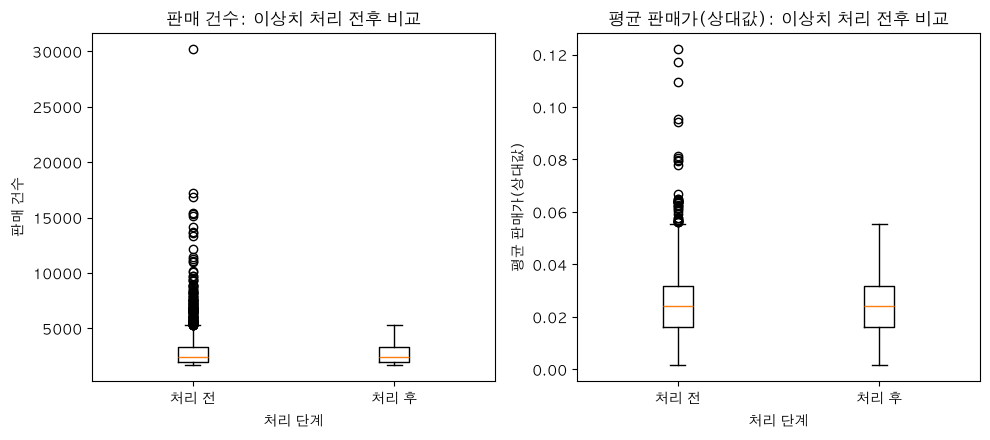

In [42]:
# 처리 전후 박스플롯
names = {"sales_count": "판매 건수", "avg_price": "평균 판매가(상대값)"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, column in zip(axes, ["sales_count", "avg_price"]):
    ax.boxplot([articles[column], articles[f"{column}_clipped"]], tick_labels=["처리 전", "처리 후"])
    ax.set_title(f"{names[column]}: 이상치 처리 전후 비교")
    ax.set_xlabel("처리 단계")
    ax.set_ylabel(names[column])
plt.tight_layout()
plt.show()

In [43]:
# 처리 전후 평균·표준편차·최댓값
rows = []
for column in ["sales_count", "avg_price"]:
    for label, series in [("처리 전", articles[column]), ("처리 후", articles[f"{column}_clipped"])]:
        rows.append({"컬럼": column, "구분": label, "평균": series.mean(),
                     "표준편차": series.std(), "최댓값": series.max()})
pd.DataFrame(rows).round(4)

,컬럼,구분,평균,표준편차,최댓값
0,sales_count,처리 전,3000.9987,1906.0904,30209.0000
1,sales_count,처리 후,2786.0040,1088.0303,5285.2500
2,avg_price,처리 전,0.0256,0.0129,0.1221
3,avg_price,처리 후,0.0253,0.0115,0.0555


In [44]:
# 거래 amount: 처리하지 않지만, 처리했다면 금액 합계가 어떻게 달라지는지 본다.
amount = analyzer.transactions["amount"]
lower, upper = analyzer.iqr_bounds("transactions", "amount")
n_outliers = len(analyzer.detect_outliers("transactions", "amount"))
total, clipped_total = amount.sum(), amount.clip(lower, upper).sum()
print(f"amount 이상치(임계값 1.5): {n_outliers:,}건 ({n_outliers / len(amount) * 100:.2f}%)")
print(f"금액 합계: 원본 {total:.4f} -> 경계값으로 바꾸면 {clipped_total:.4f} ({(clipped_total / total - 1) * 100:.1f}%)")

amount 이상치(임계값 1.5): 1,727건 (6.23%)
금액 합계: 원본 779.9242 -> 경계값으로 바꾸면 747.9368 (-4.1%)


**해석 — 이상치 처리**

- **수치 근거:** `sales_count`는 Q1 1954.0, Q3 3286.5, IQR 1332.5이고 경계는 -44.75 ~ 5285.25다. 임계값 1.5에서는 위쪽 이상치가 128개(8.53%), 아래쪽은 0개이고, 임계값 3.0에서는 52개(3.47%)로 줄어든다. `avg_price`는 1.5에서 40개(2.67%), 3.0에서 9개(0.60%)다.
- **시사점:** 이상치 개수는 임계값을 어떻게 정하느냐에 따라 달라지는 기준이지 고정된 사실이 아니다. 이상치가 모두 위쪽에만 있는 것은 두 컬럼이 오른쪽으로 길게 치우친 분포이기 때문이고, 이런 분포에서는 IQR 방식이 긴 꼬리 쪽을 많이 이상치로 판정한다.
- **수치 근거:** 경계값으로 바꾼 뒤 `sales_count`의 표준편차는 1906.0904에서 1088.0303로, 평균은 3000.9987에서 2786.0040로, 최댓값은 30209에서 5285.25로 달라졌다. `avg_price`의 표준편차는 0.0129에서 0.0115로 줄었다.
- **시사점:** 극단값의 영향이 줄어 값이 훨씬 좁은 범위에 모인다. 다만 이상치 상품은 잘못 기록된 값이 아니라 실제로 많이 팔린 상품(예: 판매 30209건)이므로, 처리한 컬럼은 통계·상관이 극단값에 좌우되지 않게 보는 용도로 쓰고 "어떤 상품이 얼마나 잘 팔리는가"를 볼 때는 원본을 써야 한다. 두 컬럼에서 이상치로 판정된 상품은 합쳐서 168개(11.2%)다.
- **수치 근거:** 거래 `amount`는 이상치가 1,727건(6.23%)이고, 경계값으로 바꾸면 금액 합계가 779.9242에서 747.9368(-4.1%)로 줄어든다.
- **시사점:** 큰 금액을 잘라내면 고객이 실제로 쓴 금액이 작아져 RFM의 Monetary가 왜곡되므로 `amount`는 처리하지 않고 원본을 쓴다.

## 7. 통계 분석과 시각화

앞에서 만든 피처와 처리한 값으로 상품·고객·거래의 분포와 변수 사이의 관계를 살펴본다. 계산은 `DataAnalyzer`의 `summarize()`(요약 통계), `correlation()`(상관계수), `monthly_sales()`(월별 매출)가 하고, 차트는 이 노트북에서 그린다.

**읽는 법**

- **평균과 중앙값:** 평균이 중앙값보다 훨씬 크면 큰 값 몇 개가 평균을 끌어올린 것이다. 25%(Q1)와 75%(Q3)는 값을 줄 세웠을 때 1/4, 3/4 지점의 값이다.
- **왜도(skewness):** 분포의 기울어진 정도다. 0이면 좌우 대칭, 양수면 오른쪽으로 긴 꼬리, 음수면 왼쪽으로 긴 꼬리다.
- **상관계수:** -1에서 1 사이의 값이다. 1에 가까우면 한쪽이 커질 때 다른 쪽도 커지고, -1에 가까우면 한쪽이 커질 때 다른 쪽이 작아지며, 0에 가까우면 그런 경향이 약하다. **상관이 있다고 원인과 결과가 있다는 뜻은 아니다.** 피어슨은 값 자체의 직선 관계, 스피어만은 값의 순위 사이의 관계를 본다.

**결정과 이유**

- **요약 통계는 처리하지 않은 원본 값으로 구한다.** 데이터를 있는 그대로 설명하기 위해서다. 이상치 처리 전후의 차이는 6장에서 봤다.
- **상관계수는 이상치를 경계값으로 바꾼 `avg_price_clipped`, `sales_count_clipped`로 구하고, 원본 값의 피어슨·스피어만으로 같은 결론인지 확인한다.** 극단값 몇 개가 상관을 좌우하지 않도록 하기 위해서다.
- **상관은 상품 단위(상품 1,500개)로 본다.** 가격·판매량과 상품명·이미지 피처가 모두 상품 테이블에 있기 때문이다.
- **번호 컬럼(`product_type_no` 등)은 통계에서 제외한다.** 숫자로 저장되어 있어도 평균이나 상관이 의미 없는 번호표다.

### 7-1. 기술 통계

In [45]:
product_columns = ["avg_price", "sales_count", "img_mean", "img_std", "prod_name_word_count", "prod_name_length"]
analyzer.summarize("articles", product_columns).round(4)

,count,mean,median,std,min,q1,q3,max
avg_price,1500,0.0256,0.0242,0.0129,0.0016,0.0161,0.0319,0.1221
sales_count,1500,3000.9987,2387.0000,1906.0904,1675.0000,1954.0000,3286.5000,30209.0000
img_mean,1500,189.1305,190.9811,29.4112,30.1297,168.6946,212.8384,237.1736
img_std,1500,62.7910,70.8214,31.1368,2.6406,38.7876,89.8535,117.5609
prod_name_word_count,1500,2.7493,3.0000,1.2180,1.0000,2.0000,4.0000,6.0000
prod_name_length,1500,15.5407,15.0000,6.7884,3.0000,10.0000,21.0000,30.0000


In [46]:
# 고객 나이와 거래 금액
pd.concat({"customers": analyzer.summarize("customers", ["age"]),
           "transactions": analyzer.summarize("transactions", ["amount"])}).round(4)

,,count,mean,median,std,min,q1,q3,max
customers,age,2000,35.6730,31.0000,14.0062,17.0000,24.0000,48.0000,79.0000
transactions,amount,27728,0.0281,0.0254,0.0187,0.0007,0.0169,0.0339,0.3373


**해석 — 기술 통계**

- **수치 근거:** 상품 `sales_count`는 평균 3000.9987, 중앙값 2387, Q1 1954, Q3 3286.5이고 최댓값은 30209다.
- **시사점:** 평균이 중앙값보다 크고 최댓값이 Q3보다 훨씬 커서, 소수의 베스트셀러가 평균을 끌어올린다. 상품의 보통 판매량을 말할 때는 평균보다 중앙값이 적절하다.
- **수치 근거:** `img_std`는 평균 62.7910가 중앙값 70.8214보다 작다.
- **시사점:** 이번에는 평균이 중앙값보다 작으므로 값이 낮은 쪽(대비가 낮은 이미지)에 긴 꼬리가 있다. 분포가 한쪽으로 기운 방향이 컬럼마다 다르다.
- **수치 근거:** 고객 나이는 평균 35.6730세, 중앙값 31세이고, 25%가 24세 이하, 75%가 48세 이하다.
- **시사점:** 절반이 31세 이하이고 하위 25%는 24세 이하인 반면 상위 25%는 48세를 넘는다. 젊은 층이 중심이고 나이 많은 고객이 평균을 중앙값보다 높이는 구조다.
- **수치 근거:** 거래 금액 `amount`는 평균 0.0281, 중앙값 0.0254, Q1 0.0169, Q3 0.0339, 최댓값 0.3373다.
- **시사점:** 가운데 절반의 거래가 0.0169~0.0339에 모여 있는데 최댓값은 Q3보다 훨씬 커서, 소수의 큰 거래가 있는 오른쪽으로 긴 분포다. 금액은 상대값이므로 비율로 해석한다.

### 7-2. 분포 — 히스토그램과 왜도

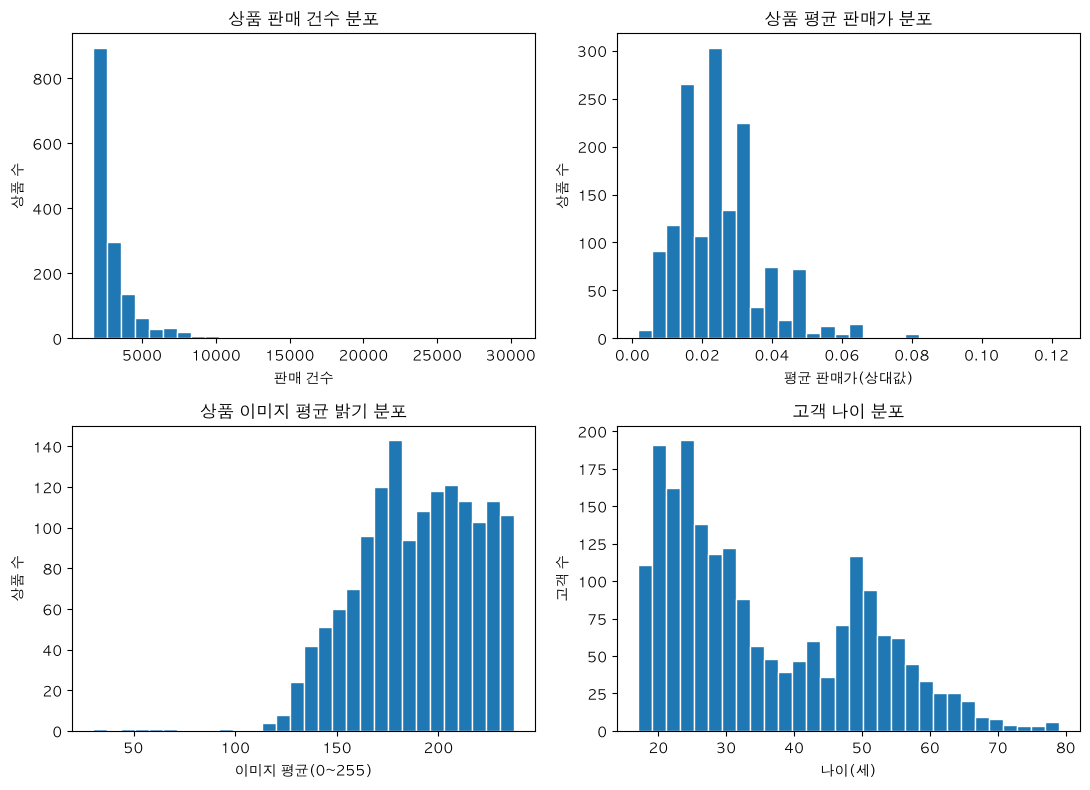

왜도(0이면 대칭, 양수면 오른쪽 꼬리, 음수면 왼쪽 꼬리):
{'판매 건수': 4.57, '평균 판매가': 1.67, '이미지 평균': -0.55, '나이': 0.65}


In [47]:
articles = analyzer.articles
customers = analyzer.customers
panels = [
    (articles["sales_count"], "상품 판매 건수 분포", "판매 건수", "상품 수"),
    (articles["avg_price"], "상품 평균 판매가 분포", "평균 판매가(상대값)", "상품 수"),
    (articles["img_mean"], "상품 이미지 평균 밝기 분포", "이미지 평균(0~255)", "상품 수"),
    (customers["age"], "고객 나이 분포", "나이(세)", "고객 수"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (values, title, xlabel, ylabel) in zip(axes.ravel(), panels):
    ax.hist(values, bins=30, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
plt.tight_layout()
plt.show()

print("왜도(0이면 대칭, 양수면 오른쪽 꼬리, 음수면 왼쪽 꼬리):")
print({"판매 건수": round(float(articles["sales_count"].skew()), 2), "평균 판매가": round(float(articles["avg_price"].skew()), 2),
       "이미지 평균": round(float(articles["img_mean"].skew()), 2), "나이": round(float(customers["age"].skew()), 2)})

**해석 — 분포**

- **수치 근거:** 왜도는 판매 건수 4.57, 평균 판매가 1.67, 이미지 평균 -0.55, 나이 0.65이다.
- **시사점:** 판매 건수와 평균 판매가는 오른쪽으로 긴 꼬리(대부분 낮은 값 + 소수의 큰 값)이고 나이도 오른쪽으로 다소 기울며, 이미지 평균은 반대로 왼쪽에 꼬리가 있다. 이 때문에 판매 건수와 평균 판매가에는 6장의 이상치 처리가 필요했고, 분포가 한쪽으로 기운 컬럼은 평균보다 중앙값으로 설명하는 편이 적절하다.

### 7-3. 상관 분석 — 상관행렬, 히트맵, 산점도

In [48]:
corr_columns = ["avg_price_clipped", "sales_count_clipped", "img_mean", "img_std",
                "prod_name_word_count", "prod_name_length"]
corr = analyzer.correlation("articles", corr_columns)  # 피어슨
corr.round(3)

,avg_price_clipped,sales_count_clipped,img_mean,img_std,prod_name_word_count,prod_name_length
avg_price_clipped,1.000,-0.137,-0.126,0.137,0.028,0.049
sales_count_clipped,-0.137,1.000,-0.018,0.060,0.163,0.132
img_mean,-0.126,-0.018,1.000,-0.877,0.064,0.093
img_std,0.137,0.060,-0.877,1.000,0.049,0.036
prod_name_word_count,0.028,0.163,0.064,0.049,1.000,0.892
prod_name_length,0.049,0.132,0.093,0.036,0.892,1.000


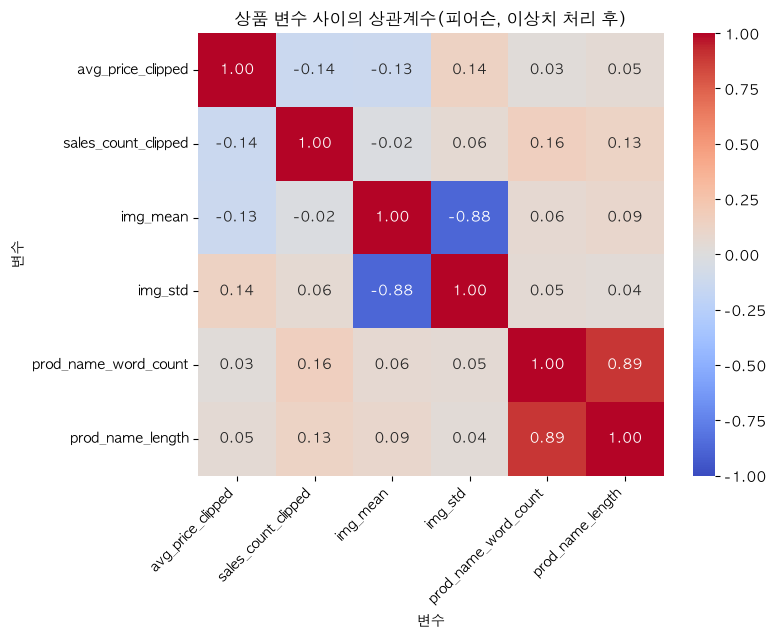

In [49]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("상품 변수 사이의 상관계수(피어슨, 이상치 처리 후)")
ax.set_xlabel("변수")
ax.set_ylabel("변수")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [50]:
# 해석할 변수 쌍: 처리 후 피어슨, 원본 피어슨, 원본 스피어만(순위 상관)을 비교한다.
original_columns = ["avg_price", "sales_count", "img_mean", "img_std", "prod_name_word_count", "prod_name_length"]
pearson_original = analyzer.correlation("articles", original_columns)
spearman_original = analyzer.correlation("articles", original_columns, method="spearman")

use_column = lambda name: name + "_clipped" if name in ("avg_price", "sales_count") else name
pairs = [("prod_name_word_count", "prod_name_length"), ("img_mean", "img_std"), ("avg_price", "sales_count")]
rows = []
for x_name, y_name in pairs:
    rows.append({"변수 쌍": f"{x_name} - {y_name}",
                 "피어슨(처리 후)": corr.loc[use_column(x_name), use_column(y_name)],
                 "피어슨(원본)": pearson_original.loc[x_name, y_name],
                 "스피어만(원본)": spearman_original.loc[x_name, y_name]})
pair_table = pd.DataFrame(rows).set_index("변수 쌍")
pair_table.round(3)

,피어슨(처리 후),피어슨(원본),스피어만(원본)
변수 쌍,,,
prod_name_word_count - prod_name_length,0.892,0.892,0.903
img_mean - img_std,-0.877,-0.877,-0.951
avg_price - sales_count,-0.137,-0.111,-0.122


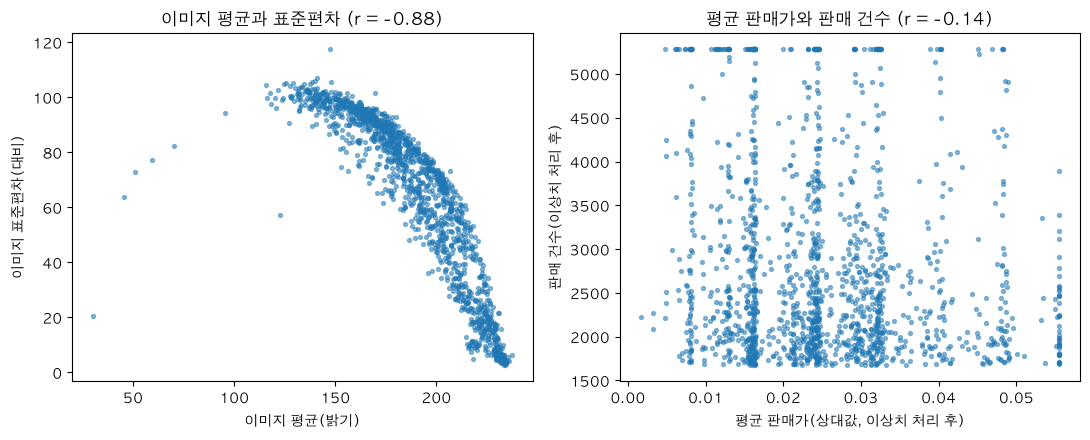

In [51]:
# 강한 관계(이미지 평균-표준편차)와 약한 관계(가격-판매량)를 산점도로 비교한다.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
r_strong = pair_table.iloc[1, 0]
axes[0].scatter(articles["img_mean"], articles["img_std"], s=8, alpha=0.5)
axes[0].set_title(f"이미지 평균과 표준편차 (r = {r_strong:.2f})")
axes[0].set_xlabel("이미지 평균(밝기)")
axes[0].set_ylabel("이미지 표준편차(대비)")

r_weak = pair_table.iloc[2, 0]
axes[1].scatter(articles["avg_price_clipped"], articles["sales_count_clipped"], s=8, alpha=0.5)
axes[1].set_title(f"평균 판매가와 판매 건수 (r = {r_weak:.2f})")
axes[1].set_xlabel("평균 판매가(상대값, 이상치 처리 후)")
axes[1].set_ylabel("판매 건수(이상치 처리 후)")
plt.tight_layout()
plt.show()

**해석 — 상관 분석**

- **수치 근거:** 상품명의 단어 수와 글자 수의 상관계수는 0.892(피어슨, 처리 후)이고 원본 피어슨 0.892, 스피어만 0.903다.
- **시사점:** 단어가 많은 이름이 글자도 많은 것은 당연한 결과이고, 두 피처가 거의 같은 정보를 담고 있다는 뜻이다. 이후 예측 등에 쓴다면 둘 중 하나만으로 충분하다.
- **수치 근거:** 이미지 평균과 표준편차의 상관계수는 -0.877(피어슨), -0.951(스피어만)로 강한 음의 관계다.
- **시사점:** 이미지가 밝을수록 밝고 어두운 부분의 차이(대비)가 작은 경향이 강하다. 산점도는 직선이 아니라 위로 볼록한 곡선 모양이라서, 순위 기준인 스피어만이 피어슨보다 절댓값이 크다. 밝고 단조로운 배경의 사진이 많기 때문일 수 있으나 이 노트북에서 원인까지 확인하지는 않았다. 확실한 것은 두 피처가 비슷한 정보를 일부 중복해서 담고 있다는 점이다.
- **수치 근거:** 평균 판매가와 판매 건수의 상관계수는 -0.137(처리 후 피어슨), -0.111(원본 피어슨), -0.122(스피어만)로 모두 0에 가깝다.
- **시사점:** 가격이 높은 상품이 덜 팔리는 약한 경향이 있어 보이지만 그 정도가 매우 작아서, 가격만으로 판매량을 설명할 수 없다. 처리 전후와 피어슨·스피어만이 같은 결론이므로 극단값 때문에 생긴 결과가 아니다(산점도 위쪽의 가로줄은 이상치를 경계값으로 바꾼 상품들이다). 상관은 원인과 결과를 말하지 않는다.

### 7-4. 월별 매출 추이 — 라인차트

In [52]:
monthly = analyzer.monthly_sales()
monthly.round({"total_amount": 3, "daily_avg": 3})

,month,orders,total_amount,days,days_in_month,is_partial,daily_avg
0,2019-09-01,863,25.581,8,30,True,3.198
1,2019-10-01,2279,73.287,31,31,False,2.364
2,2019-11-01,2130,66.356,30,30,False,2.212
3,2019-12-01,2172,58.970,31,31,False,1.902
4,2020-01-01,2194,58.225,31,31,False,1.878
5,2020-02-01,1644,46.557,29,29,False,1.605
6,2020-03-01,1906,56.035,31,31,False,1.808
7,2020-04-01,2326,66.327,30,30,False,2.211
8,2020-05-01,2514,69.576,31,31,False,2.244
9,2020-06-01,3580,89.731,30,30,False,2.991


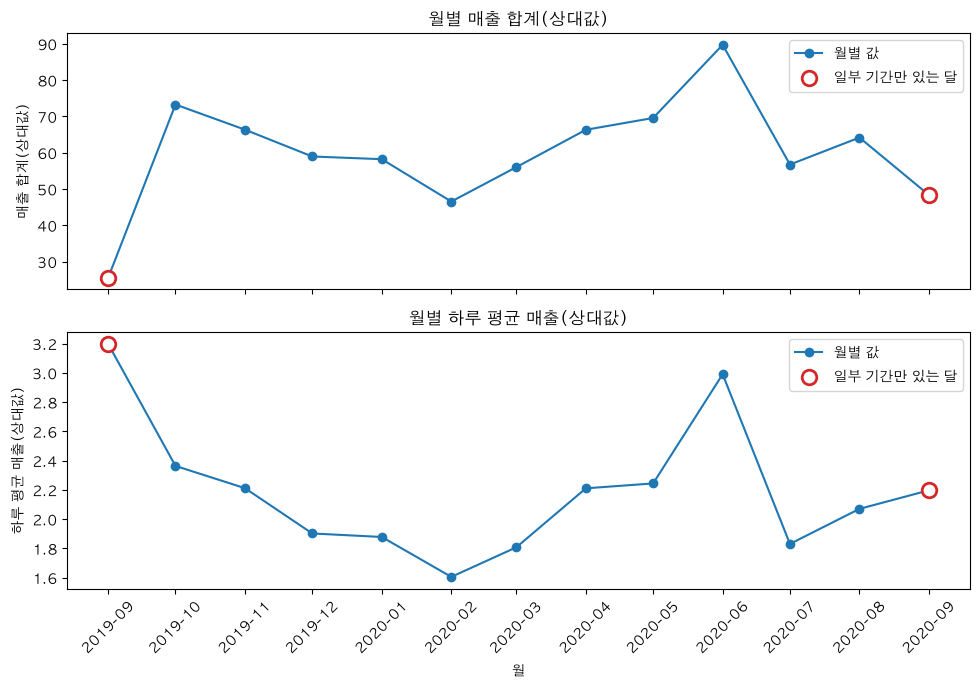

In [53]:
import matplotlib.dates as mdates

partial = monthly[monthly["is_partial"]]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
panels = [("total_amount", "월별 매출 합계(상대값)", "매출 합계(상대값)"),
          ("daily_avg", "월별 하루 평균 매출(상대값)", "하루 평균 매출(상대값)")]
for ax, (column, title, ylabel) in zip(axes, panels):
    ax.plot(monthly["month"], monthly[column], marker="o", color="tab:blue", label="월별 값")
    ax.scatter(partial["month"], partial[column], s=110, facecolors="white", edgecolors="tab:red",
               linewidths=2, zorder=3, label="일부 기간만 있는 달")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend()
axes[1].set_xlabel("월")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].set_xticks(monthly["month"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**해석 — 월별 매출 추이**

- **수치 근거:** 매출 합계(`amount`의 합)는 2020-06에 89.731(거래 3,580건)로 가장 크다. 첫 달 2019-09은 8일치 데이터라 합계가 25.581, 마지막 달 2020-09은 22일치라 48.343이지만, 하루 평균은 2019-09이 3.198, 2020-09이 2.197다.
- **시사점:** 합계만 보면 첫 달과 마지막 달이 작아 보이지만 그것은 판매가 줄어서가 아니라 데이터가 일부 기간만 있어서다. 달마다 기간이 다를 때는 하루 평균으로 비교해야 한다.
- **수치 근거:** 온전한 달 중 하루 평균이 가장 낮은 달은 2020-02(1.605)이고, 가장 높은 달은 2020-06이다(하루 평균 2.991).
- **시사점:** 월별로 매출의 높낮이가 뚜렷하게 오르내린다. 다만 이 데이터는 1년치뿐이고 원인(계절, 행사 등)을 알려 주는 정보가 없어서, 높낮이의 이유는 이 분석으로 알 수 없다.

## 8. RFM 값 계산

**RFM**은 고객이 얼마나 "단골"인지를 세 숫자로 나타내는 방법이다.

| 이름 | 뜻 | 단골일수록 |
| --- | --- | --- |
| **R**ecency(최근성) | 기준일에서 마지막 구매일까지 지난 날수 | **작다**(최근에 왔다) |
| **F**requency(빈도) | 기간 중 구매한 횟수 | 크다 |
| **M**onetary(금액) | 기간 중 쓴 금액의 합 | 크다 |

`DataAnalyzer.calculate_rfm()`이 거래 데이터에서 고객별로 이 세 값을 계산한다. 점수를 매기고 고객을 그룹으로 나누는 일은 다음 장에서 한다.

**결정과 이유**

- **Frequency는 서로 다른 구매일의 수다.** 거래 1행은 상품 1개라서, 같은 날 여러 상품을 사면 여러 행이 생긴다. 행 수로 세면 하루에 많이 산 고객이 자주 온 고객처럼 부풀려진다. 이 과제는 "자주 오는 고객"을 찾는 것이므로 방문한 날의 수로 센다.
- **Recency의 기준일은 인자로 받고, 기본값은 거래 데이터의 마지막 날짜다.** 기준일에 구매한 고객은 Recency가 0이다. 기준일이 정해져 있지 않으면 새 데이터나 다른 시점에 같은 코드를 쓸 수 없어서 하드코딩하지 않는다.
- **기준일이 어떤 고객의 마지막 구매일보다 이르면 오류를 낸다.** 조용히 일부 거래를 빼면 고객 수와 값이 말없이 달라지고, 음수 Recency는 의미가 없기 때문이다. 기준일을 데이터보다 뒤로 미루는 것은 허용한다.
- **Monetary는 금액의 합이다.** 거래 금액은 상대값이므로 고객별 금액도 상대값이다.
- **결측 규칙.** 고객 ID나 날짜가 없는 행은 뺀다. 금액이 없는 행은 구매일로는 세고 금액에는 0으로 더한다. 이 데이터에는 결측이 없다.

In [54]:
rfm = analyzer.calculate_rfm()
print(f"RFM 표: {len(rfm):,}행 (고객 수 {analyzer.customers['customer_id'].nunique():,}명)")
rfm.head()

RFM 표: 2,000행 (고객 수 2,000명)


,customer_id,recency,frequency,monetary
0,00511323d252c93be07a61a61891bc8ff0ffdf547573fcafa96807e1349b4636,17,9,1.269458
1,006614ef971c0097e28a98c8c1d7127088c7dae2721eac3c8174457ee4746cba,198,1,0.025407
2,006e3b308be2c29584e79e4c87df8c7fd45ebe5ce2bbb89910927872c0a9c6b7,27,3,0.155780
3,006e4ef0f8243b60eb0e94c1d851254f8cf0ce45fbb8b889fcd187832c2beaa3,36,1,0.127068
4,00998ab46e0ad7e77e4ea9dc0e2109c15e055d0c20acfc62dbca43f8ee9f3e2a,41,5,0.407017


In [55]:
summary = rfm[["recency", "frequency", "monetary"]]
display(summary.describe().round(4))
for name, column in [("Recency", "recency"), ("Frequency", "frequency"), ("Monetary", "monetary")]:
    s = rfm[column]
    print(f"{name}: 평균 {s.mean():g}, 중앙값 {s.median():g}, Q1 {s.quantile(0.25):g}, Q3 {s.quantile(0.75):g}, 최솟값 {s.min():g}, 최댓값 {s.max():g}")
print("R, F, M 사이의 스피어만 상관계수:")
summary.corr(method="spearman").round(3)

,recency,frequency,monetary
count,2000.0000,2000.0000,2000.0000
mean,117.2675,4.3130,0.3900
std,102.4316,5.3674,0.5502
min,0.0000,1.0000,0.0068
25%,29.0000,1.0000,0.0796
50%,87.0000,2.0000,0.1955
75%,186.2500,5.0000,0.4523
max,365.0000,62.0000,4.8426


Recency: 평균 117.267, 중앙값 87, Q1 29, Q3 186.25, 최솟값 0, 최댓값 365
Frequency: 평균 4.313, 중앙값 2, Q1 1, Q3 5, 최솟값 1, 최댓값 62
Monetary: 평균 0.389962, 중앙값 0.195466, Q1 0.0795678, Q3 0.452267, 최솟값 0.00676271, 최댓값 4.84261
R, F, M 사이의 스피어만 상관계수:


,recency,frequency,monetary
recency,1.000,-0.574,-0.489
frequency,-0.574,1.000,0.816
monetary,-0.489,0.816,1.000


In [56]:
# 고객 2명을 거래에서 직접 집계해 RFM 표의 행과 비교한다.
transactions = analyzer.transactions
reference_date = transactions["order_date"].max()
print("기준일(거래의 마지막 날짜):", reference_date.date())

def check_customer(customer_id, label):
    mine = transactions[transactions["customer_id"] == customer_id]
    last_purchase = mine["order_date"].max()
    recency = (reference_date - last_purchase).days
    frequency = mine["order_date"].nunique()
    monetary = mine["amount"].sum()
    row = rfm[rfm["customer_id"] == customer_id].iloc[0]
    print(f"[{label}] 고객 {customer_id[:10]}...: 거래 {len(mine)}행")
    print(f"  직접 집계: 마지막 구매 {last_purchase.date()} -> Recency {recency}일, 구매일 {frequency}일 -> Frequency {frequency}, 금액 합 {monetary:.4f}")
    print(f"  RFM 표   : Recency {row['recency']}일, Frequency {row['frequency']}, Monetary {row['monetary']:.4f}")
    print("  일치:", recency == row["recency"] and frequency == row["frequency"] and abs(monetary - row["monetary"]) < 1e-9)

most_frequent = rfm.loc[rfm["frequency"].idxmax(), "customer_id"]
rows_per_customer = transactions.groupby("customer_id").size()
one_day_many_rows = rows_per_customer[rfm.set_index("customer_id")["frequency"].reindex(rows_per_customer.index) == 1].idxmax()
check_customer(most_frequent, "가장 자주 온 고객")
check_customer(one_day_many_rows, "하루에 여러 상품을 산 고객")

기준일(거래의 마지막 날짜): 2020-09-22
[가장 자주 온 고객] 고객 51c16c02b7...: 거래 103행
  직접 집계: 마지막 구매 2020-09-20 -> Recency 2일, 구매일 62일 -> Frequency 62, 금액 합 2.0673
  RFM 표   : Recency 2일, Frequency 62, Monetary 2.0673
  일치: True
[하루에 여러 상품을 산 고객] 고객 6801ea7e5b...: 거래 43행
  직접 집계: 마지막 구매 2020-03-17 -> Recency 189일, 구매일 1일 -> Frequency 1, 금액 합 0.8840
  RFM 표   : Recency 189일, Frequency 1, Monetary 0.8840
  일치: True


In [57]:
# 극단 고객과 합계를 확인한다.
total_rows = len(rfm)
print(f"Recency = 0인 고객(기준일에 구매): {(rfm['recency'] == 0).sum()}명")
print(f"Recency 최댓값: {rfm['recency'].max()}일 / 해당 고객 {(rfm['recency'] == rfm['recency'].max()).sum()}명")
print(f"금액 합계: RFM 표 {rfm['monetary'].sum():.4f} / 거래 전체 {transactions['amount'].sum():.4f}")
pairs = transactions[["customer_id", "order_date"]].drop_duplicates().shape[0]
print(f"구매일 수 합계: RFM 표 {rfm['frequency'].sum():,} / 거래에서 서로 다른 (고객, 구매일) 쌍 {pairs:,}")
one_time = (rfm["frequency"] == 1).sum()
print(f"구매일이 1일뿐인 고객: {one_time:,}명 ({one_time / total_rows * 100:.1f}%)")
top = rfm["monetary"].nlargest(200).sum() / rfm["monetary"].sum() * 100
print(f"금액 상위 10%(200명)의 금액 비중: {top:.1f}%")
multi = (transactions.groupby(["customer_id", "order_date"]).size() > 1).mean() * 100
print(f"같은 날 2행 이상인 (고객, 구매일) 비율: {multi:.1f}%")

Recency = 0인 고객(기준일에 구매): 20명
Recency 최댓값: 365일 / 해당 고객 2명
금액 합계: RFM 표 779.9242 / 거래 전체 779.9242
구매일 수 합계: RFM 표 8,626 / 거래에서 서로 다른 (고객, 구매일) 쌍 8,626
구매일이 1일뿐인 고객: 698명 (34.9%)
금액 상위 10%(200명)의 금액 비중: 44.2%
같은 날 2행 이상인 (고객, 구매일) 비율: 68.3%


In [58]:
# 기준일을 바꿔 호출한다. 기준일을 30일 뒤로 미루면 Recency만 30씩 늘어야 한다.
later = analyzer.calculate_rfm(reference_date=reference_date + pd.Timedelta(days=30))
print("Recency 증가분:", sorted(int(x) for x in (later["recency"] - rfm["recency"]).unique()))
print("Frequency·Monetary 동일:", later[["frequency", "monetary"]].equals(rfm[["frequency", "monetary"]]))
print("문자열 기준일도 가능:", analyzer.calculate_rfm(reference_date="2020-09-22").equals(rfm))
try:
    analyzer.calculate_rfm(reference_date="2020-09-01")
except ValueError as error:
    print("마지막 구매일보다 이른 기준일:", error)

Recency 증가분: [30]
Frequency·Monetary 동일: True
문자열 기준일도 가능: True
마지막 구매일보다 이른 기준일: 기준일(2020-09-01)이 마지막 구매일(2020-09-22)보다 이르다. 기준일은 모든 고객의 마지막 구매일 이후여야 한다.


**해석 — RFM 값**

- **수치 근거:** 고객 2,000명의 Recency는 중앙값 87일, Q1 29일, Q3 186.25일이고 0~365일에 걸쳐 있다. 기준일에 구매한 고객은 20명, 가장 오래전(Recency 365일)에 마지막으로 구매한 고객은 2명이다.
- **시사점:** 고객의 절반이 87일 안에 다녀갔고, 4분의 1은 186.25일이 넘도록 오지 않았다. 최근에 온 고객과 오래 오지 않은 고객이 모두 상당수라서 최근성은 고객을 구분하는 기준으로 쓸 수 있다.
- **수치 근거:** Frequency(구매일 수)는 평균 4.313, 중앙값 2, 최댓값 62이고, 구매일이 1일뿐인 고객이 698명(34.9%)이다.
- **시사점:** 평균이 중앙값보다 크고 최댓값이 매우 커서 소수의 아주 자주 오는 고객이 평균을 끌어올린다. 한 번만 온 고객이 3분의 1을 넘으므로 이들을 "단골 후보"와 구분하는 기준이 필요하다.
- **수치 근거:** Monetary(금액 합)는 중앙값 0.195466, 평균 0.389962, 최댓값 4.84261이고, 금액 상위 10%(200명)가 전체 금액의 44.2%를 차지한다.
- **시사점:** 소수의 고객이 금액의 상당 부분을 낸다. 이 고객들을 따로 관리하는 전략의 근거가 되며, 점수를 나눌 때 금액의 치우침을 감안해야 한다.
- **수치 근거:** 스피어만 상관계수는 Frequency–Monetary 0.816, Recency–Frequency -0.574, Recency–Monetary -0.489이다.
- **시사점:** 자주 온 고객일수록 많이 쓰고, 최근에 온 고객일수록 더 자주 오고 더 많이 쓰는 경향이 있다. Frequency와 Monetary는 비슷한 정보를 일부 중복해서 담고 있다. 이 값들은 상관일 뿐 원인과 결과를 말하지 않는다.